# 07 - Water Saturation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/07_water_saturation.ipynb)

**Part A - Petrophys Curriculum**

Water saturation ($S_w$) is the fraction of the pore space occupied by formation
water. It is the single most consequential number in a petrophysical evaluation:
the hydrocarbon saturation is simply $S_h = 1 - S_w$, and everything downstream -
net pay, bulk-volume water, volumetrics - flows from it.

This lesson is the centrepiece of Part A. We build up from the classic **Archie**
equation for clean formations, then work through the four main **shaly-sand**
corrections (Simandoux, Indonesia, and the regional North Sea and Nigeria forms),
compare them head to head on a real shaly interval, set out what the lab-data
Waxman-Smits / Dual-Water pair needs before it can run, derive Archie's $m$ and $n$
from a **Pickett plot**,
compute flushed-zone saturation $S_{xo}$, and finally show how the model choice
changes when we move from a **clastic** reservoir to a **carbonate** one.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

By the end of this lesson you will be able to:

- State the Archie equation and its assumptions, and know when it breaks down.
- Explain the physical idea behind each shaly-sand model and choose between them.
- Run each model with `pp.interpret(..., sw_model=...)`, compare them on a real
  interval, and know what Waxman-Smits and Dual-Water need before they can run.
- Read the automatic, sample-by-sample model routing of `sw_model="auto"`.
- Read $m$ and $R_w$ off a Pickett plot's water line.
- Compute flushed-zone saturation $S_{xo}$ and understand what it tells you.
- Interpret a **carbonate** reservoir with the well's own header Archie
  parameters, and contrast it with the clastic workflow.

## Why this matters

Resistivity logs do not measure hydrocarbons - they measure how hard it is for an
electric current to pass through the rock. Water conducts; hydrocarbons and the
rock matrix do not. Archie's insight (1942) was that in a **clean, water-wet**
rock the resistivity relates to porosity and water saturation through simple power
laws:

$$ S_w^{\,n} = \frac{a\,R_w}{\phi^{m}\,R_t} $$

- $R_t$ - true (deep) formation resistivity, $\Omega\!\cdot\!m$
- $R_w$ - formation-water resistivity, $\Omega\!\cdot\!m$
- $\phi$ - porosity (effective, v/v)
- $a$ - tortuosity factor (often 1)
- $m$ - cementation exponent (~2 for clean sands)
- $n$ - saturation exponent (~2, water-wet)

The trouble: **clay** is also conductive (it holds bound water and has surface
charge). In a shaly sand Archie reads the clay conductivity as if it were extra
formation water and reports $S_w$ that is **too high** (too pessimistic). The
shaly-sand models exist to remove that clay conductivity term in different ways.

### Prerequisites

This lesson assumes you have worked through the earlier Part A lessons on data
access, clay volume (`Vcl`), porosity and formation water (lesson 06).
`pp.interpret` computes `Vcl` and the effective porosity `PHIE` the saturation
models need, so the lesson runs standalone.

In [2]:
import pandas as pd
import petrophys as pp

pd.set_option("display.max_colwidth", None)   # show the trace's decisions in full

## 1. Load the teaching well

Our clastic teaching well is **30/6-5** (North Sea, depths in metres). The core
data and the Brent Group sandstone reservoir (`BRENT GP.` in the bundled
tops: Ness Fm 2841-2865 m, Etive Fm 2865-2958 m) both sit around 2841-2958 m, so
we focus there. Every saturation model needs three inputs:

1. **Vcl** - the clay volume, here the minimum of the gamma-ray and
   neutron-density indicators (lesson 03).
2. **Porosity** - the effective porosity `PHIE` (lesson 04): total porosity less
   the clay-bound water, $\phi_t - V_{cl}\,\phi_{cl}$, corrected to the core plugs
   where the well has them. The shaly-sand models assume effective porosity.
3. **Rt** - approximated by the deep resistivity `RDEP`. Strictly, $R_t$ is the
   resistivity of the *uninvaded* formation; the deep reading equals it only where
   invasion is shallow relative to the tool's depth of investigation. Lesson 06
   showed conductive invasion in the upper Brent Group sands, where deep invasion
   pulls `RDEP` toward the lower $R_{xo}$ and biases $S_w$ slightly high. Taking
   the deep reading as $R_t$ is standard practice, but it is an assumption worth
   naming.

> **Note**
>
> This LAS labels its core saturations `SWC` and `SOC` as fractions, but they
> hold percentages. Petrophys divides them by 100 when it reads the core data and
> says so with a `UserWarning` each time. Formation summaries also note, once per
> call, the formations outside the reservoir where the core-calibrated permeability
> is undefined at some net-pay samples. The next cell hides only those messages; lesson 02 covers core-unit conversion.

In [3]:
import warnings

warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")
warnings.filterwarnings("ignore", message=r"PERM_CC is undefined at some net-pay samples")
well = pp.read(pp.sample("30_6-5"), formations=pp.sample("formations_30_6-5"))
brent = "2841 <= DEPTH <= 2958"   # the Brent Group reservoir

### Where is saturation before calculating it?

A LAS may contain **core saturation** (`SWC`, `SOC`) without a calculated **log
saturation** (`SW`). Plotting shows the data that exist: the saturation track of
the raw well holds core points, not a continuous saturation curve. The viewer
converts the core percentages to fractions on a display copy; the well itself is
not changed.

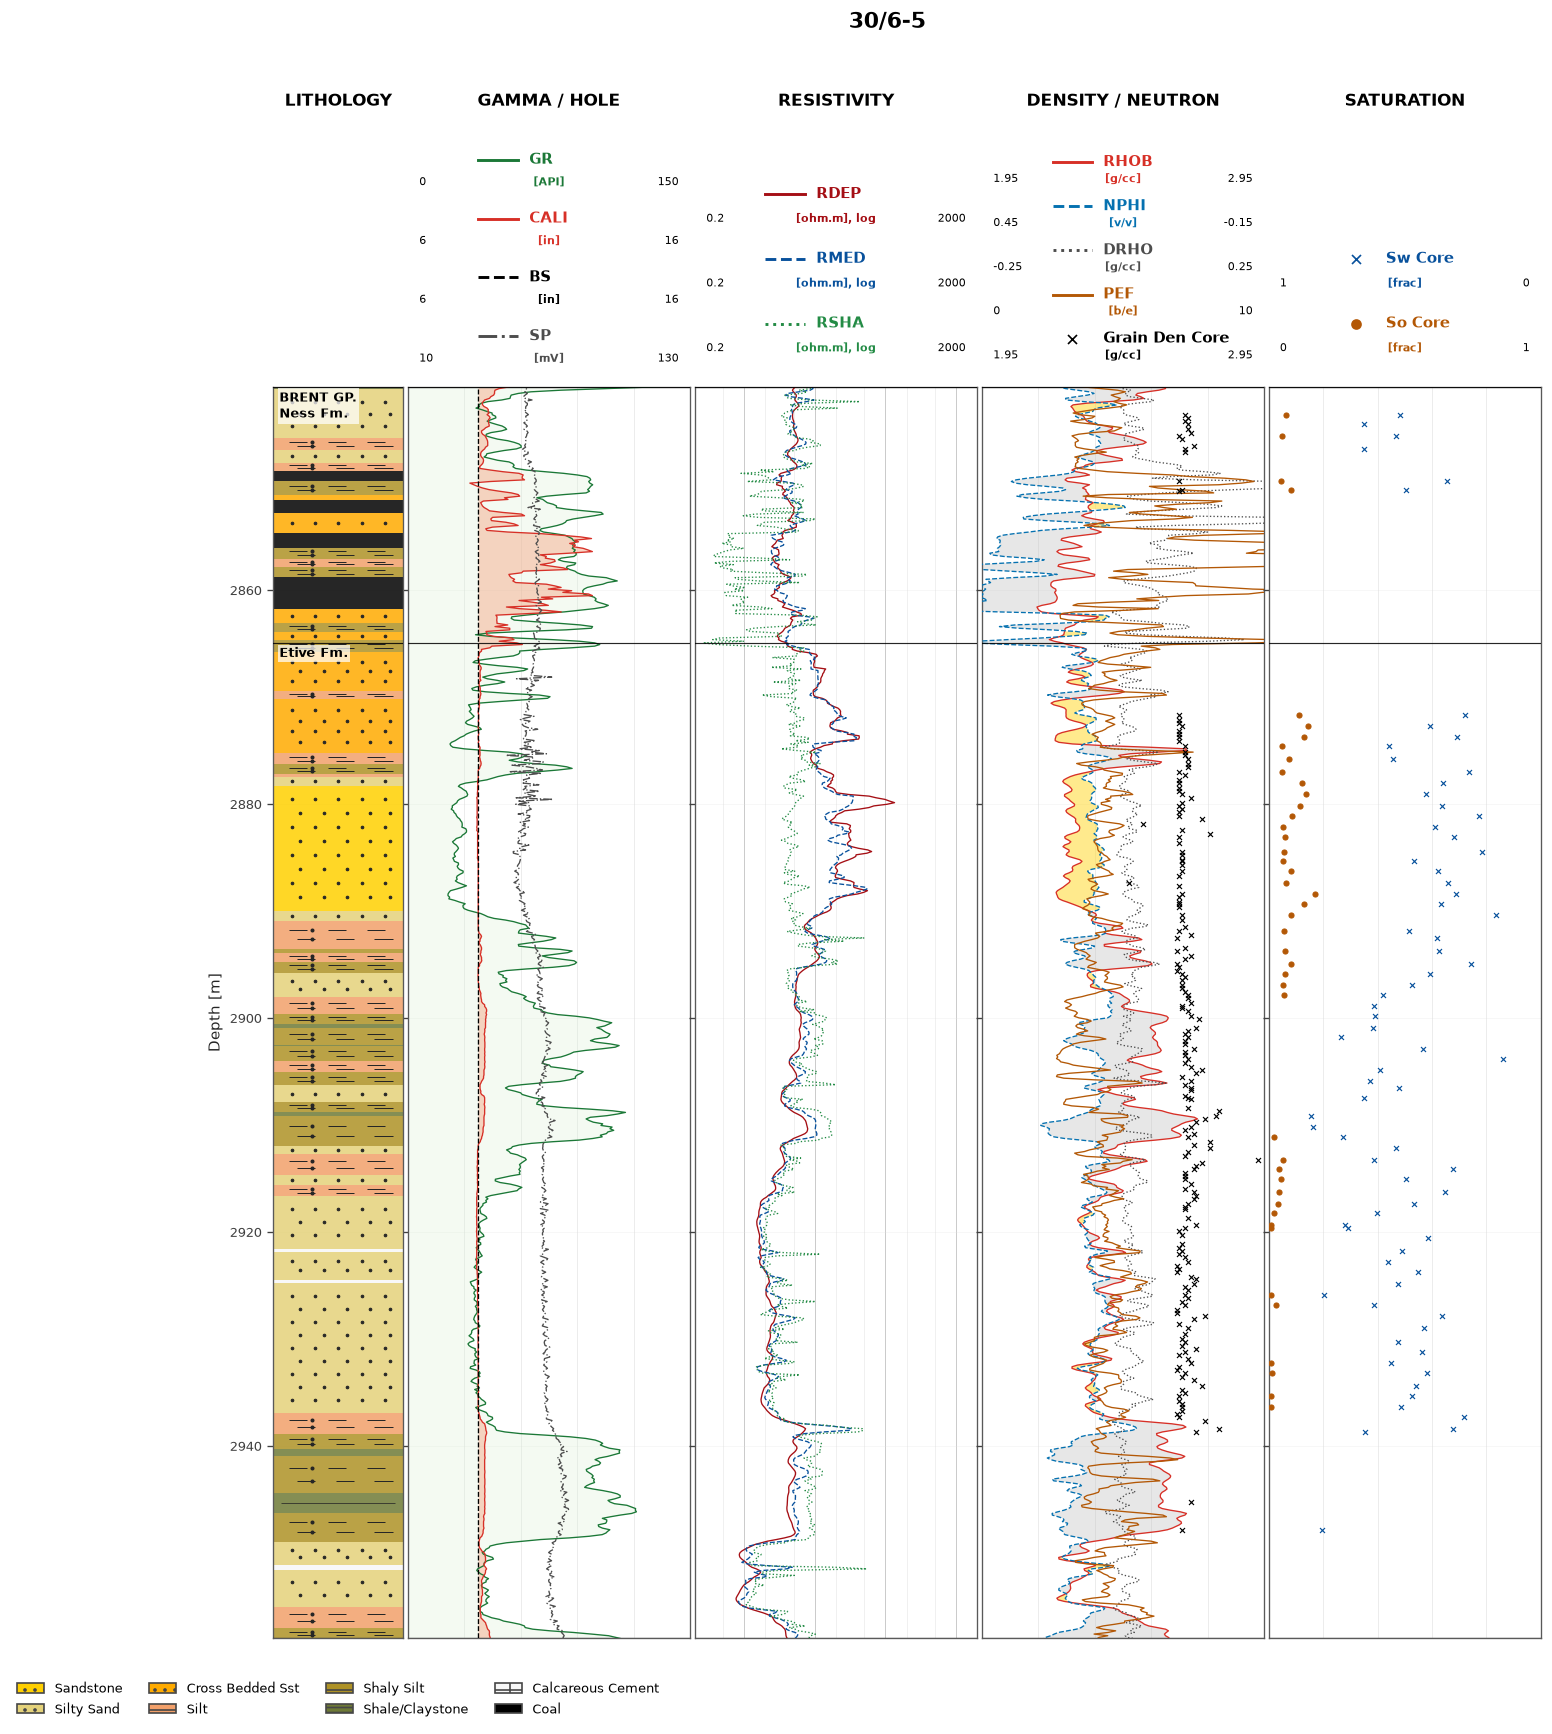

In [4]:
pp.plot(well, top=2841, bottom=2958,
        tracks=["LITHOLOGY", "GAMMA / HOLE", "RESISTIVITY", "DENSITY / NEUTRON", "SATURATION"])

## 2. Archie - the clean-formation baseline

For a **clean** rock (little to no clay) Archie is all you need:

$$ S_w = \left( \frac{a\,R_w}{\phi^{m}\,R_t} \right)^{1/n} $$

We need a value for $R_w$ and the Archie constants. The LAS header carries the
operator's evaluation value, `RW` = 0.070 ohm.m at `RWT` = 230 degF (NPD well
data), and lesson 06 showed that independent salinity and SP estimates agree with
it. So we use the operator's parameters (lesson 09 compares our net pay with that
evaluation): $R_w = 0.070\,\Omega\!\cdot\!m$ at 230 degF, moved along the
temperature profile, with $a = 0.8$ and $m = n = 2$ instead of the textbook
$a = 1$. They are settings of `pp.interpret`, and `sw_model="archie"` applies
Archie at every depth.

**Assumptions baked into Archie:**

- The rock is clean (no conductive clay).
- The rock is water-wet and the pore network is well connected.
- $R_w$, $m$, $n$ are known and roughly constant over the interval.

When clay is present these assumptions fail and Archie over-estimates $S_w$.

In [5]:
operator = dict(rw=0.07, rw_meas_temp_f=230, a=0.8, m=2, n=2)
archie = pp.interpret(well, **operator, sw_model="archie")
archie.statistics(top=2841, bottom=2958)

,unit,samples,mean,p10,median,p90
VCL,v/v,768,0.355891,0.010977,0.233212,0.834522
PHIT,v/v,768,0.200452,0.129854,0.203638,0.263334
PHIE,v/v,768,0.128011,0.000000,0.147506,0.231630
SW,v/v,768,0.801130,0.230940,1.000000,1.000000
PERM,mD,636,74.265033,0.002416,21.733693,259.456209


Over the Brent Group, Archie's $S_w$ ranges from about 0.09 in the cleanest,
most resistive sand to 1 (fully water-bearing); its median is 1 because the
interval contains as much shale and wet sand as oil-bearing sand. Shale has
almost no effective porosity, so Archie returns $S_w = 1$ there.

## 3. Shaly-sand models - removing the clay conductivity

Each model adds a term for the extra current the clay carries, so that only the
*free* formation water is counted. They split into two families by what they
need:

**Field-data forms** - everything comes from the logs you already have
($V_{cl}$, a shale resistivity picked off the log, and the Archie constants):

| Model | `sw_model` | Core idea | Best when |
|-------|------------|-----------|-----------|
| **Simandoux** | `"simandoux"` | Parallel clay-conductance term $V_{cl}/R_{cl}$ | Higher salinity ($\gtrsim$ 20 kppm), dispersed clay |
| **Indonesia** (Poupon-Leveaux) | `"indonesia"` | Clay and sand conductance add as square roots, weighted by $V_{cl}$ | Fresher water, laminated/dispersed clay |
| **North Sea** (regional) | `"north_sea"` | Laminated-shale term $V_{sh}^{\,e}/R_{tsh}$ on the conductivity side | North Sea shaly sands - the local convention for this very well |
| **Nigeria-type** (Sodir-report form, regional) | `"nigeria_schlumberger"` | Fixed shale term subtracted in square-root space | Niger-delta-style laminated sands |

**Lab-data forms** - they model the clay path more physically, but need
laboratory inputs no log can give:

| Model | Extra inputs | Where the inputs come from |
|-------|--------------|----------------------------|
| **Waxman-Smits** | $\phi_t$, CEC, $B$ | CEC from core (wet chemistry) |
| **Dual-Water** | $\phi_t$, $R_{wb}$, $\phi_{cl}$ | SCAL / regional clay studies |

Without those measurements the lab-data forms would run on guesses, so the
working comparison below uses the **four field-data forms**; section 4 sets out
what the lab-data pair needs, and why neither this lesson nor the library runs it
on guessed inputs.

### The governing equations (as implemented)

- **Archie** (the baseline all of these reduce to at $V_{cl}=0$):

$$ S_w = \left( \frac{a\,R_w}{\phi^m\,R_t} \right)^{1/n} $$

- **Simandoux**: clay adds a parallel conductance term that is *linear* in $S_w$
  (solved exactly as a quadratic for $n=2$, numerically otherwise):

$$ \frac{1}{R_t} = \frac{\phi^m}{a\,R_w}\,S_w^{\,n} + \frac{V_{cl}}{R_{cl}}\,S_w $$

- **Indonesia** (Poupon-Leveaux): clay and sand conduction paths add in
  square-root space, with $S_w^{n/2}$ as a common factor on both:

$$ \frac{1}{\sqrt{R_t}} = \left[ \frac{V_{cl}^{\,1-V_{cl}/2}}{\sqrt{R_{cl}}}
   + \frac{\phi^{m/2}}{\sqrt{a\,R_w}} \right] S_w^{\,n/2} $$

- **Waxman-Smits** (Waxman and Smits, 1968): clay conductivity from the
  cation-exchange capacity (CEC in meq/g in this form), on total porosity, solved
  by fixed-point iteration:

$$ C_t = \frac{S_w^{\,n}}{F^{*}} \left( C_w + \frac{B\,Q_v}{S_w} \right),
   \qquad Q_v = \frac{CEC \cdot \rho_{ma}\,(1-\phi_t)}{\phi_t} $$

- **Dual-Water** (Clavier, Coates and Dumanoir, 1984): split the pore water
  into bound and free fractions on total porosity; the bound fraction of the
  water present, $S_{wb}/S_{wt}$, conducts with the bound-water resistivity.
  The library solves this for $S_{wt}$ (a quadratic for $n=2$, iteration
  otherwise) and then strips the bound water back out:

$$ S_{wb} = \frac{V_{cl}\,\phi_{cl}}{\phi_t}, \qquad
   \frac{1}{R_t} = \frac{\phi_t^m\,S_{wt}^{\,n}}{a}
   \left[ \frac{1}{R_w} + \frac{S_{wb}}{S_{wt}}
   \left( \frac{1}{R_{wb}} - \frac{1}{R_w} \right) \right], \qquad
   S_{we} = \frac{S_{wt}-S_{wb}}{1-S_{wb}} $$

The two regional variants: a **Nigeria-type** form as used in the Sodir reports,
which subtracts a fixed shale term in square-root space,
$S_w = \big[(1/\sqrt{R_t} - V_{cl}^{\,c}/\sqrt{R_{sh}}) \big/ (\phi^{m/2}/\sqrt{a R_w})\big]^{2/n}$
(the textbook Nigeria equation applies $S_w^{n/2}$ to both the sand and the shale
terms), and the **North Sea** laminated form,
$S_w^{\,n} = (1/R_t - V_{sh}^{\,e}/R_{tsh})\,a R_w/\phi^m$, with the shale exponent
`vsh_exp` (default 1.6).

The clay (shale) resistivity $R_{cl}$ comes from the well itself: the workflow takes
the median deep resistivity of the shale-lithology samples (setting `rtsh` replaces
it). Run all five models on the same inputs - one setting changes:

In [6]:
models = ["archie", "simandoux", "indonesia", "north_sea", "nigeria_schlumberger"]
runs = {model: pp.interpret(well, **operator, sw_model=model) for model in models}
archie.step("rcl").decisions

['Rcl = 2.91 ohm.m (median RT in shale lithology samples, n=1172)']

In [7]:
pd.concat({model: r.statistics(["SW"], top=2841, bottom=2958) for model, r in runs.items()}).round(3)

,,unit,samples,mean,p10,median,p90
archie,SW,v/v,768,0.801,0.231,1.000,1.0
simandoux,SW,v/v,768,0.690,0.225,0.716,1.0
indonesia,SW,v/v,768,0.688,0.226,0.763,1.0
north_sea,SW,v/v,627,0.710,0.205,0.889,1.0
nigeria_schlumberger,SW,v/v,694,0.702,0.203,0.909,1.0


### Reading the numbers

All four shaly-sand models return a **lower** mean $S_w$ than Archie (about 0.69-0.71
against 0.80). That is the whole point - Archie mistook clay conductivity for
water, so removing it frees up more of the pore volume for hydrocarbons. The two
regional forms leave some samples empty (`valid` below 768): where the shale term
alone exceeds the measured conductivity, the model does not apply and returns NaN.
Interval averages hide where the models agree and where they differ, so split the
interval by clay volume:

In [8]:
logs = {model: r.well.to_dataframe().query(brent) for model, r in runs.items()}
pd.DataFrame({model: df.groupby(pd.cut(df["VCL"], [0, 0.2, 0.3, 0.6, 1.0], include_lowest=True))["SW"].mean()
              for model, df in logs.items()}).round(3)

,archie,simandoux,indonesia,north_sea,nigeria_schlumberger
VCL,,,,,
"(-0.001, 0.2]",0.617,0.600,0.578,0.608,0.604
"(0.2, 0.3]",0.899,0.851,0.804,0.870,0.859
"(0.3, 0.6]",0.955,0.845,0.820,0.899,0.858
"(0.6, 1.0]",0.955,0.643,0.718,0.602,0.655


### Interpreting the divergence

- **In clean rock** (`Vcl` up to 0.2) all four models stay within 0.04 of
  Archie - their correction terms scale with $V_{cl}$ and vanish with the clay. That collapse
  is the sanity check: a shaly-sand model that disagrees with Archie in clean rock
  is mis-parameterised.
- **In shaly rock** (`Vcl` 0.3-0.6) they fan out. Simandoux and Indonesia, whose
  clay terms are coupled to $S_w$, correct most; the North Sea and Nigeria forms
  subtract a fixed shale conductance and leave NaN where it exceeds the measured
  conductivity, so their means cover fewer samples.
- **In shale** (`Vcl` above 0.6) Archie reads close to 1, but the shaly-sand
  models read 0.60-0.72. Wherever a shale is more resistive than the shale
  resistivity $R_{cl}$ (the median of all shale samples), the clay term explains
  less than the whole conductivity and the models assign the rest to hydrocarbon.
  These saturations describe almost no fluid: the workflow's effective porosity
  removes the clay-bound water, so shale has almost no effective porosity left,
  and the clay and porosity cutoffs keep it out of net pay. Compare models on net
  rock only, and always pair the shaly-sand models with effective porosity: with
  a porosity that still counts the clay-bound water they correct twice.
- The **spread between the models** is your uncertainty band. When they
  disagree strongly you are sensitive to $R_{cl}$ and the shale exponent - the
  parameters you know least well - and should calibrate against core or SCAL.

What the choice costs in practice is pay. With the same cutoffs, the net pay of each
Brent Group formation under each model:

In [9]:
pd.DataFrame({model: r.formation_summary().set_index("Formation").loc[["Ness Fm.", "Etive Fm."], "Net Pay (m)"]
              for model, r in runs.items()}).round(1)

,archie,simandoux,indonesia,north_sea,nigeria_schlumberger
Formation,,,,,
Ness Fm.,2.9,4.3,4.4,3.5,4.1
Etive Fm.,23.3,26.4,26.5,25.6,25.9


The shaly Ness Formation is where the model matters: Simandoux and Indonesia book
about half as much pay again as Archie. In the clean Etive Formation the models
differ by about 3 m in 23-27 m.

### Compare the models over depth

`pp.plot` with `curves=` draws several results in one figure, one track per curve
and one line per result; given the mapping of runs, it names each line by its model.

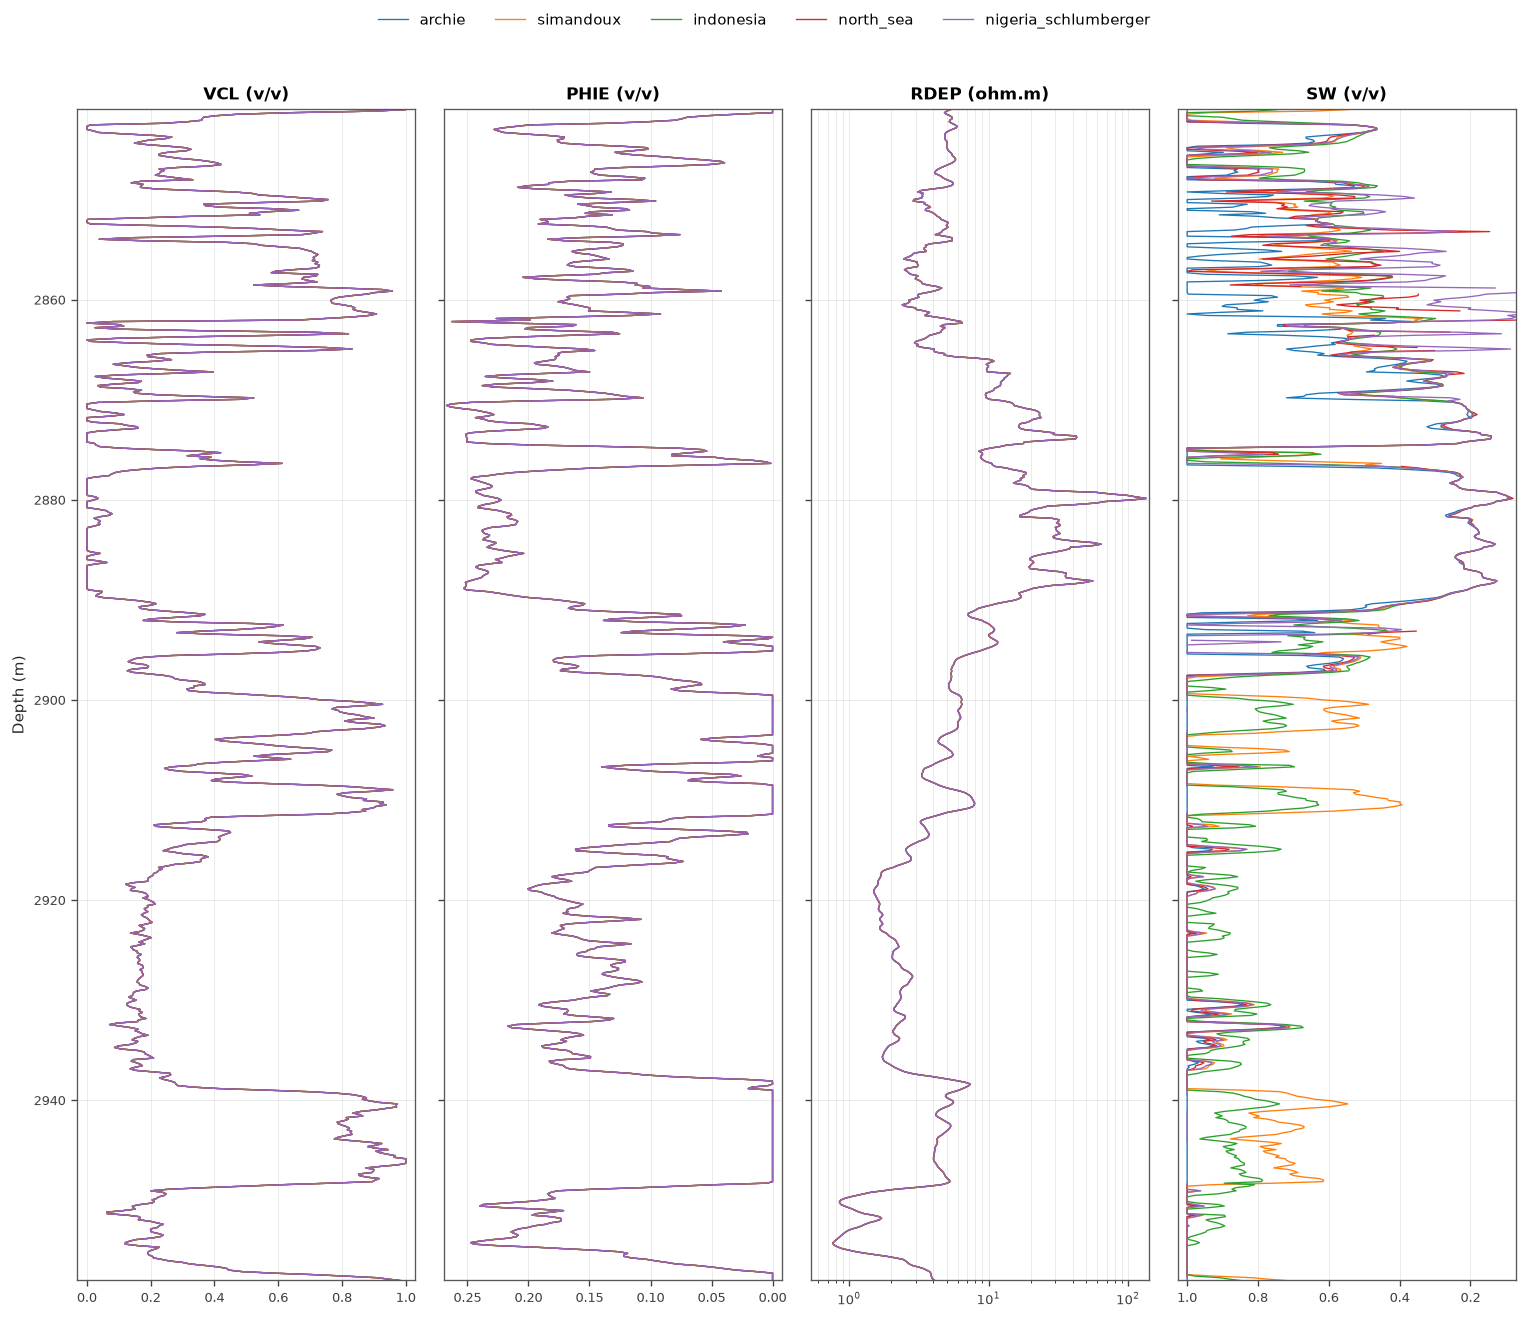

In [10]:
pp.plot(runs, curves=["VCL", "PHIE", "RDEP", "SW"], top=2841, bottom=2958)

The `VCL`, `PHIE` and `RDEP` tracks are the same for every run (the lines overlap);
only `SW` changes. The models coincide in the clean, resistive Etive sand around
2870-2895 m and separate in the shaly beds of the Ness Formation and around 2900 m
and 2945 m.

## 4. The lab-data family: Waxman-Smits and Dual-Water

The library also implements the two lab-calibrated models. They are the right
tools **when the laboratory inputs exist**:

- **Waxman-Smits** needs the cation-exchange capacity from core wet chemistry
  (setting `cec`) and the equivalent counter-ion conductance $B$, in
  (S/m)/(meq/cm$^3$) (`b_coeff`). It works on total porosity.
- **Dual-Water** needs the bound-water resistivity $R_{wb}$ (`rwb`) and the clay
  porosity $\phi_{cl}$ (`phi_cl`), from SCAL or a regional clay study.

30/6-5 has none of these measurements: a CEC or an $R_{wb}$ chosen without data
would only turn an assumption into a saturation. The library holds to the same rule
and never estimates them: `pp.interpret` runs Waxman-Smits only when you supply
`cec` and `b_coeff`, and Dual Water only with `rwb`. Forcing Dual Water without
`rwb` stops the saturation step with an error that says what is missing:

In [11]:
pp.interpret(well, **operator, sw_model="dual_water").errors

["saturation: sw_model='dual_water' needs the bound-water resistivity rwb (ohm.m), from lab data or an RWB LAS header parameter; it is not estimated. sw_model='auto' uses Dual Water only where rwb is given."]

#### Why the library does not guess

A guessed $R_{wb}$ or CEC is not a neutral placeholder. Both models take a
clay-bound water term out of the water the resistivity supports, and in shaly
rock that term can rival the total. Where a guessed input makes it too large,
$S_w$ collapses towards zero in exactly the shaliest samples: an artefact that
looks like a hydrocarbon show. The remedy is data, not a better guess - CEC and
$B$ from core, $R_{wb}$ and $\phi_{cl}$ from SCAL or a regional clay study.

**Units.** The settings take the laboratory unit for CEC, **meq/100 g**, and
divide by 100 themselves. They accept 0-150 meq/100 g (pure smectite is
80-150 meq/100 g; Grim, 1968) and warn below 1, where a value is probably in meq/g.
The workflow reports the Waxman-Smits $S_w$ on the effective-porosity basis,
$S_{we} = 1 - (\phi_t/\phi_e)(1 - S_{wt})$ (Crain's Petrophysical Handbook), so
it pairs with PHIE like every other model.

## 5. Automatic routing: `sw_model="auto"`

You rarely pick one model for a whole well. The default, `sw_model="auto"`,
decides **sample by sample** from $V_{cl}$, lithology and salinity: Archie below the
routing clay volume (`sw_routing_vcl_cutoff`, else `vcl_cutoff`, else 0.3), a
shaly-sand model above it - Waxman-Smits with `cec` and `b_coeff`, Simandoux at a
`salinity_ppm` of 20,000 or more, otherwise Indonesia - and Dual Water in shaly
carbonate only with `rwb`. One well can legitimately use several models across
depth, and the trace counts them:

In [12]:
auto = pp.interpret(well, **operator)
auto.step("saturation").decisions

['Model selected: archie+simandoux',
 'Auto-routing: depth-by-depth model selection based on VCLAY and lithology',
 'Depth routing counts: archie=10472, simandoux=11704',
 'Dual Water needs a supplied Rwb, which is not estimated: 1468 shaly carbonate samples used the Simandoux equation (set rwb to use Dual Water)',
 'Archie coefficients from lithology (vendor_lithology_log[LITHOLOGY_GEOLINK])',
 'Rw range = 0.0624 to 0.1967, Rcl = 2.906 ohm.m',
 'SXO from invaded-zone Archie where RXO/RSHA/RESS and RMF were finite; SXO = SW^(1/5) elsewhere (archie_rxo_rmf=22079, fifth_root_quicklook=92)',
 'Sw range: 0.018 - 1.000']

On this well about half the samples get Archie and half Simandoux, and the shaly
carbonate samples, without an `rwb`, take Simandoux too. No `salinity_ppm` is set,
but the given Rw (0.070 ohm.m at 230 degF) is a brine saltier than 20,000 ppm
(lesson 06: a little fresher than 35,000 ppm), so the router chooses Simandoux over
Indonesia. Over the Brent
Group the routed answer therefore follows Archie in the clean sand and Simandoux
in the shaly beds.

## 6. The Pickett plot - reading $m$ (and $R_w$)

The Pickett plot is a log-log crossplot of **porosity (x) vs $R_t$ (y)**. Taking
logs of Archie for a **100% water** rock ($S_w=1$):

$$ \log R_t = -m\,\log\phi + \log(a\,R_w) $$

So on log-log axes the water-bearing points fall on a straight line whose
**slope is $-m$** and whose position fixes $a\,R_w$. Points that plot above that
water line are hydrocarbon-bearing (higher $R_t$ at the same porosity). Solving
Archie for $R_t$ at a given $S_w$,

$$ R_t(\phi; S_w) = \frac{a\,R_w}{\phi^m \, S_w^{n}}, $$

every iso-$S_w$ line has the same slope $-m$, shifted UP by $n\,\log_{10}(1/S_w)$
decades (with $n=2$: the 80% line sits 0.19 decades above the water line, 60% at
0.44, 40% at 0.80, 20% at 1.40). Once $R_w$ and $m$ are picked, reading a point's
$S_w$ off the plot is solving Archie graphically.

**Pick the water line on its lower envelope, not by regression.** A regression
runs through the *middle* of the cloud, so half the points end up below
"$S_w=1$", which is impossible, and tight or shaly streaks flatten its slope. The
industry pick fixes $m$ at a plausible cementation exponent and slides the line down
until the wet, clean points sit on it.

**We need a water leg.** The Brent Group carries hydrocarbon over much of its
thickness, so we use the deeper, low-resistivity **Statfjord Formation sandstone
(3223-3556 m)**, which is largely water-bearing. Choosing the wettest *interval*
is the practical way round the circularity of picking water-bearing points before
knowing $R_w$ (in a real study you would confirm an aquifer with pressure gradients
from RFT/MDT). Here we draw the operator's water line, $R_w$ = 0.070 ohm.m with
$a = 0.8$, $m = n = 2$, over the Statfjord points, coloured by clay volume, and see
whether it sits on the lower edge of the clean cloud.

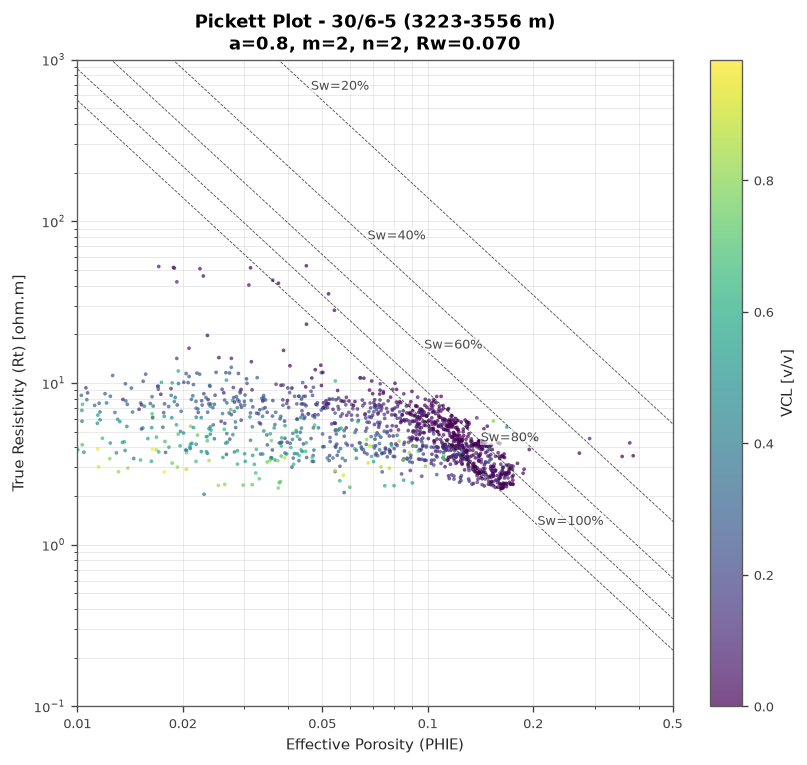

In [13]:
from petrophys.visualization import create_pickett_plot

create_pickett_plot(auto, rw=0.07, depth_range=(3223, 3556), a=0.8, m=2, n=2,
                    color_curve="VCL", figsize=(8, 7));

#### Pickett-plot check

The clean (dark, low-`Vcl`), porous Statfjord points form a band along the
$S_w = 1$ line, mostly between it and the 80 % line, with its lower edge on the
water line: the operator's $R_w$ and $m = 2$ describe this water leg. Two other
groups do not belong to it. The shaly points (light colours) plot at low porosity
and moderate resistivity, below and left of the line: clay conduction makes them
read wet beyond $S_w = 1$, a non-physical answer that says Archie does not apply
there. The few tight, resistive points in the upper left (porosity below 0.05,
$R_t$ above 20 ohm.m) are tight streaks, not hydrocarbon (the NPD records no
Statfjord discovery in this well). A regression would be pulled toward both groups;
the envelope ignores them.

The Statfjord is deeper and hotter (about 250 degF) than the Brent Group, so its
in-situ $R_w$ sits a little below the operator's value quoted at 230 degF: by Arps,
about 0.065 ohm.m, which would move the water line down by less than a tenth of a
decade. Sanity-check any Pickett $m$ against expected ranges (~1.8-2.0 for clean,
well-connected sands; 2.2-2.8 for vuggy/moldic carbonates) and against
core-measured $m$.

## 7. Flushed-zone saturation $S_{xo}$

Drilling mud filtrate invades the near-wellbore rock and flushes out moveable
hydrocarbon. The **flushed zone** therefore has its own water saturation $S_{xo}$,
computed with Archie but using the *shallow* resistivity $R_{xo}$ and the mud
filtrate resistivity $R_{mf}$:

$$ S_{xo}^{\,n} = \frac{a\,R_{mf}}{\phi^{m}\,R_{xo}} $$

Because invasion sweeps moveable oil away, $S_{xo} \ge S_w$; the gap
$S_{xo}-S_w$ is a moveability indicator (more on that in lesson 09). 30/6-5 has a
shallow curve `RSHA`, so the workflow writes a real `SXO`. It needs a trustworthy
$R_{mf}$: lesson 06 showed that the header `RMF` read at the assumed 75 degF is far
too low, and that the filtrate chloride gives the right value, so we pass it as
`rmf_chlorides_mg_l`.

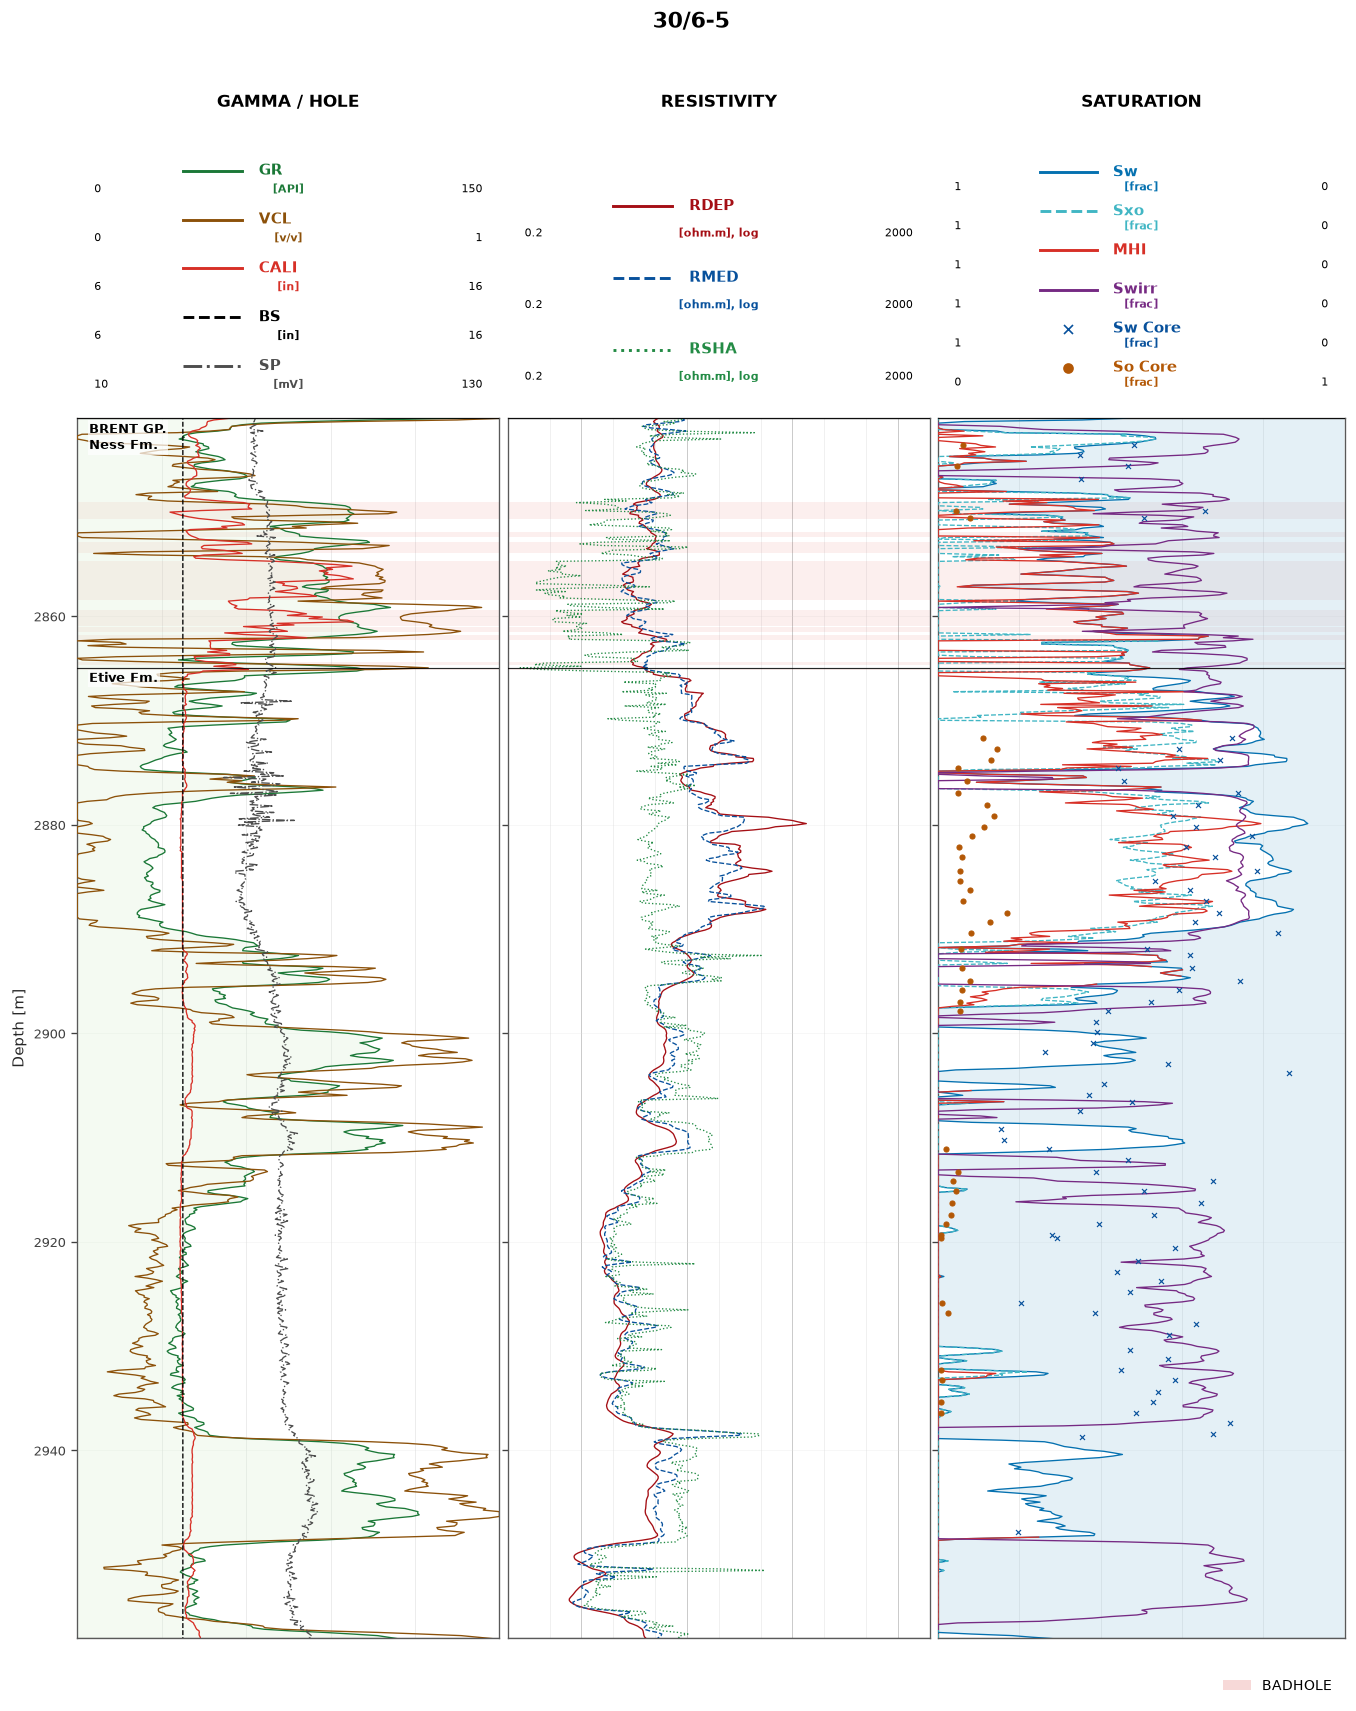

In [14]:
flushed = pp.interpret(well, **operator, rmf_chlorides_mg_l=20366)
pp.plot(flushed, top=2841, bottom=2958, tracks=["GAMMA / HOLE", "RESISTIVITY", "SATURATION"])

In [15]:
sands = flushed.well.to_dataframe().query(brent + " and VCL < 0.3")
(sands["SXO"] - sands["SW"]).groupby(pd.cut(sands["DEPTH"], [2841, 2900, 2958])).describe().round(2)

,count,mean,std,min,25%,50%,75%,max
DEPTH,,,,,,,,
"(2841, 2900]",231.0,0.18,0.12,0.0,0.07,0.19,0.26,0.64
"(2900, 2958]",206.0,0.00,0.01,0.0,0.00,0.00,0.00,0.12


#### Moveable-hydrocarbon interpretation

In the clean sands above 2900 m, where `RDEP` is high and $S_w$ low, $S_{xo}$
exceeds $S_w$ by about 0.18 on average, and by up to 0.64: mud filtrate displaced
hydrocarbon from the flushed zone, evidence that the hydrocarbon is moveable. Below
2900 m both read 1 and the gap is zero: water-bearing sand, with nothing to flush.
With the header `RMF` read at the assumed 75 degF instead, $R_{mf}$ would be less
than half as large, $S_{xo}$ correspondingly lower, and most of that moveable
hydrocarbon would be hidden (Exercise 4). Read the moveable-hydrocarbon signal in the clean
sands, as lesson 09 does with the MHI.

## 8. Carbonate model selection - Archie on a Costa well (HW-3)

Everything so far was a **clastic** North Sea sand. Carbonates behave differently:
they are usually **clean** (low $V_{cl}$), so the shaly-sand corrections are often
unnecessary - but their complex pore systems mean $m$ and $n$ drift away from 2 and
must be measured. The `petrophys` sample set includes a carbonate field ("Costa",
depths in feet); each Costa LAS file covers only the Kharaib-2 reservoir
interval, not the whole well. Well **HW-3** carries its Archie parameters in the
LAS header. Read the whole block: the header `RW` is quoted at `RWT` = 68 degF, a
surface temperature, not at the reservoir temperature.

In [16]:
hw3 = pp.read(pp.sample("HW-3"))
{name: hw3.get_parameter(name) for name in ["RW", "RWT", "A", "M", "N", "BHT", "TD"]}

{'RW': 0.0682,
 'RWT': 68.0,
 'A': 1.0,
 'M': 2.03,
 'N': 2.0,
 'BHT': 251.0,
 'TD': 8299.0}

`pp.interpret` reads all of them: `A`, `M` and `N` as the Archie constants, and `RW`
at `RWT`, moved along the temperature profile from the header BHT. Without a
lithology log the workflow interprets a well as clastic unless told otherwise, so we
say what the rock is: `lithology="carbonate"`. The provenance parameters, which
`to_las` writes into the output header, list what it used:

In [17]:
carbonate = pp.interpret(hw3, lithology="carbonate")
pd.DataFrame(carbonate.provenance_parameters())

,mnemonic,value,descr,unit
0,PP_VERSION,3.0.0,petrophys version,NaN
1,PP_STATUS,interpreted,Interpretation status,NaN
2,PP_DOMAIN,carbonate,Lithology interpretation domain,NaN
3,PP_MATRIX,limestone,Matrix used,NaN
4,PP_LITH,carbonate,Lithology family used,NaN
5,PP_RW,0.0682,Rw input at 68 degF (las_metadata_temperature_profile_corrected),ohm.m
6,PP_RWTMIN,0.02027,Minimum Rw at formation temperature,ohm.m
7,PP_RWTMAX,0.02066,Maximum Rw at formation temperature,ohm.m
8,PP_SWMODEL,archie,Water saturation model(s),NaN
9,PP_A,1.0,Archie a,NaN


The reservoir is at about 242 degF, so the 0.0682 ohm.m measured at 68 degF is
about 0.020 ohm.m in situ (`PP_RWTMIN`/`PP_RWTMAX`). The common mistake is to pass
the header number as if it were the in-situ value: `rw=0.0682` without
`rw_meas_temp_f`. The workflow then takes it at the median formation temperature
and warns that it did. Compare both with the stored `SW_INPUT`, the field's own
saturation, on the samples where all three exist:

In [18]:
mistake = pp.interpret(hw3, lithology="carbonate", rw=0.0682)
print(mistake.warnings[-1])
pd.DataFrame({"Rw from 68 degF": carbonate.well["SW"].data, "Rw 0.0682 in situ": mistake.well["SW"].data,
              "SW_INPUT": hw3["SW_INPUT"].data}).dropna().describe().round(3)

Rw 0.0682 ohm.m was given without rw_meas_temp_f: it is taken at the median formation temperature, 242.5 degF.


,Rw from 68 degF,Rw 0.0682 in situ,SW_INPUT
count,321.000,321.000,321.000
mean,0.142,0.233,0.120
std,0.167,0.187,0.145
min,0.045,0.083,0.040
25%,0.084,0.153,0.070
50%,0.101,0.185,0.090
75%,0.125,0.228,0.100
max,1.000,1.000,0.940


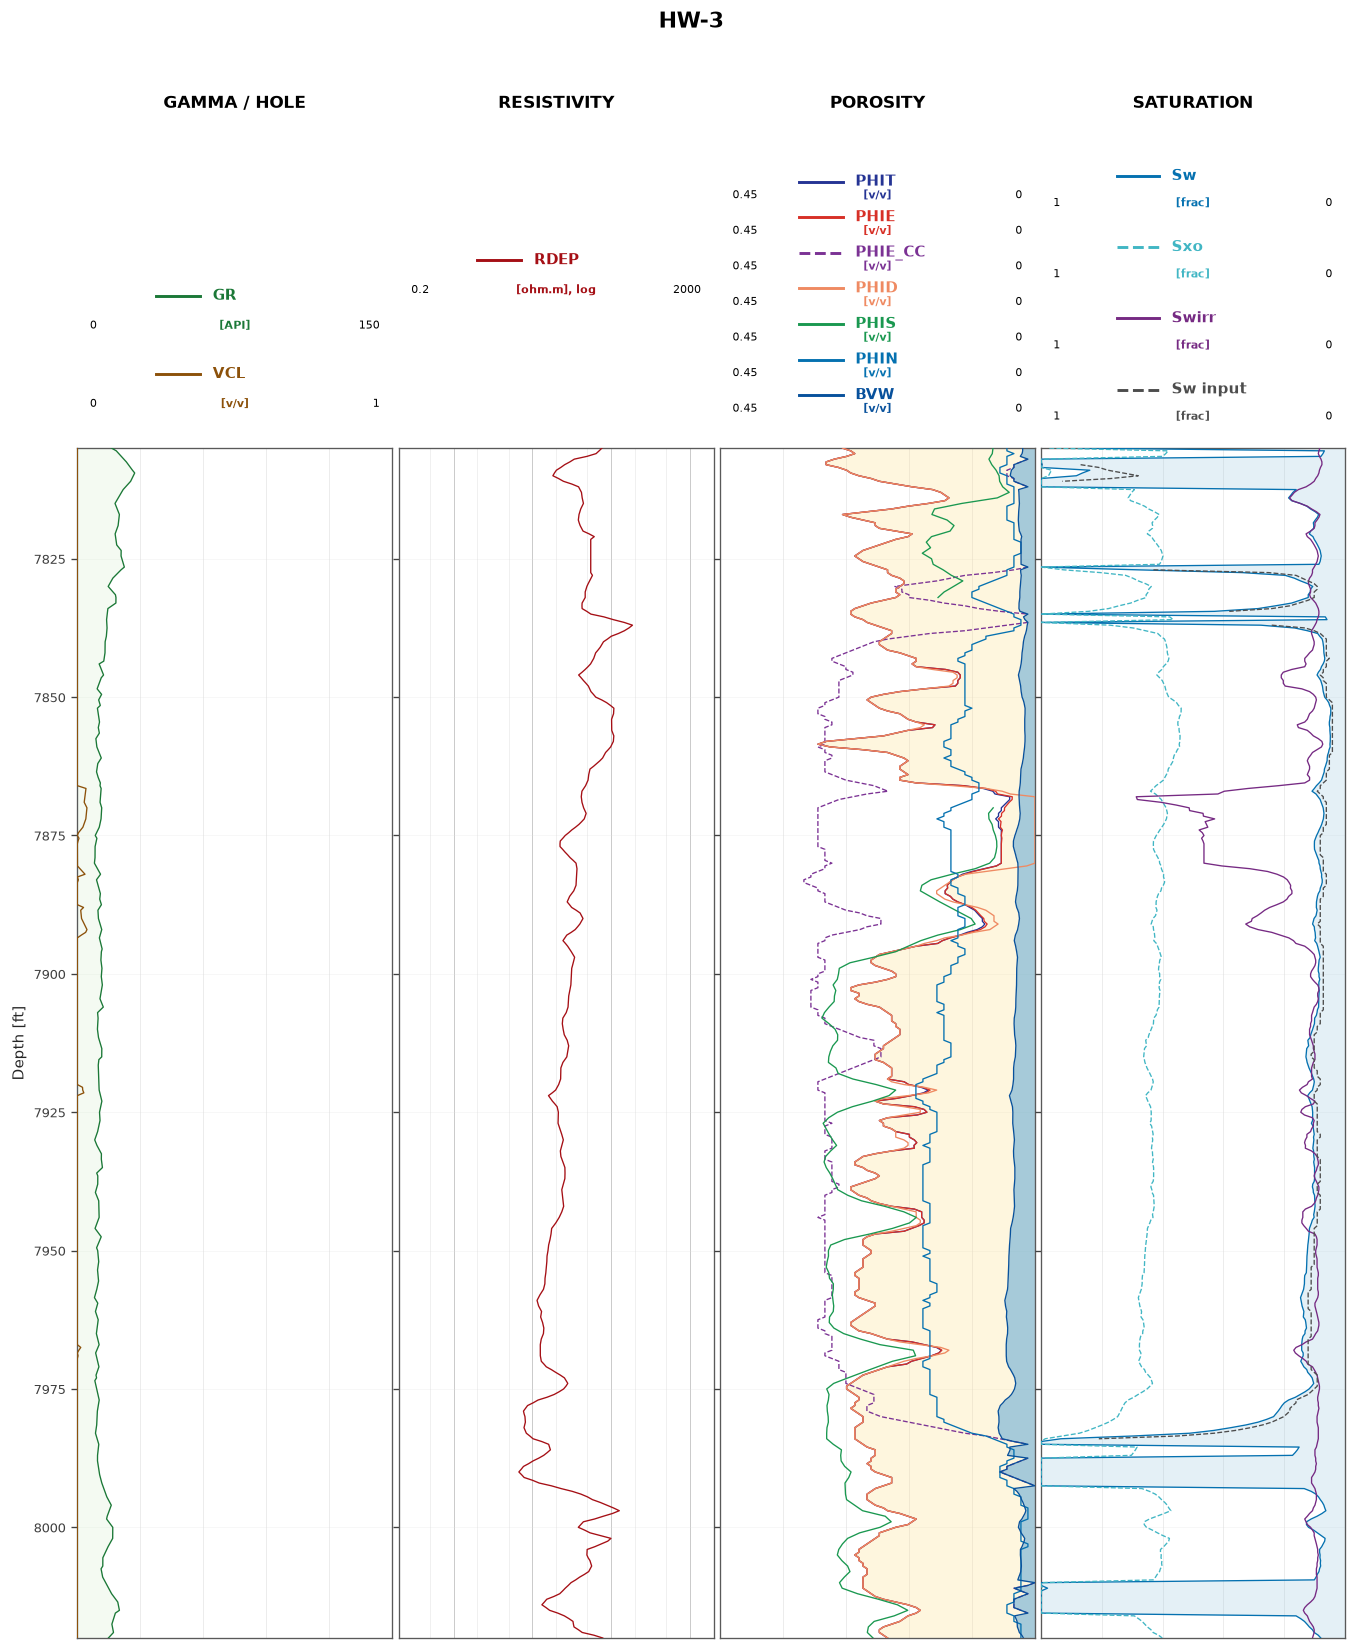

In [19]:
pp.plot(carbonate, tracks=["GAMMA / HOLE", "RESISTIVITY", "POROSITY", "SATURATION"])

### Clastic vs carbonate - which model, and why

| | Clastic (30/6-5) | Carbonate (HW-3) |
|---|---|---|
| Clay content | Variable, often high $V_{cl}$ | Very low $V_{cl}$ (clean) |
| Dominant $S_w$ problem | Clay conductivity | Complex/disconnected pore geometry |
| Model choice | Shaly-sand (Simandoux / Indonesia / regional forms) | **Archie**, but with measured $m, n$ |
| Key parameter to nail | $R_{cl}$, CEC, $R_{wb}$ | $m$ (cementation exponent), $n$ |
| Where the parameter comes from | Shale intervals, SCAL/CEC | Core / SCAL / Pickett; often in the LAS header |

The take-away: **the model is chosen by the rock, not by habit.** In clastics the
enemy is clay, so you spend your effort on shaly-sand corrections. In carbonates
the rock is clean but the pore system is wild, so you keep Archie and instead spend
your effort measuring $m$ and $n$ - which is exactly why HW-3 ships them in its
header. The workflow routed every HW-3 sample to Archie on its own.

With $R_w$ moved from 68 degF to the reservoir temperature, Archie with the header
$m$ and $n$ tracks `SW_INPUT` closely (median 0.101 against 0.090; the dashed curve
in the saturation track). Taking the 68 degF value as the in-situ $R_w$ more than
triples $R_w$ and nearly doubles $S_w$ (median 0.185). The lesson is **parameter
provenance**: a resistivity is only half a fact without its temperature, and a
header block must be read whole.

## Pitfalls & parameter choices

- **$R_w$ dominates everything.** A 2x error in $R_w$ moves $S_w$ by roughly
  $\sqrt{2}$. Get it from an SP-derived $R_w$, a water-zone Pickett line, or a
  produced-water sample - not a guess - and always give its temperature.
- **Don't use a shaly-sand model in clean rock as insurance.** It won't hurt much,
  but if $R_{cl}$/CEC are poorly known it can add noise. Route on $V_{cl}$
  (`sw_model="auto"`).
- **$m$ and $n$ are not universally 2.** Carbonates and cemented sands push $m$ up;
  oil-wet rocks push $n$ up. Both raise computed $S_w$. Measure them when the
  answer matters.
- **Check the CEC unit.** The settings take meq/100 g and convert it themselves - do
  not divide by 100 first. $B$, in (S/m)/(meq/cm$^3$), depends on temperature and
  salinity: at 25 degC $B = 4.6\,[1 - 0.6\,e^{-0.77/R_w}]$ (Waxman and Smits, 1968),
  about 1.8 in fresh water rising to 4.6 in brine, and higher at reservoir
  temperature (Waxman and Thomas, 1974). A wrong $B$ silently rescales the whole
  clay term.
- **Dual-Water and Waxman-Smits use *total* porosity**, not effective. The workflow
  reads PHIT - PHIE as clay-bound water, so both must be on the same basis.
- **$R_{cl}$ from shale**: the median deep resistivity of the shale samples is a
  reasonable field pick, but a bad shale baseline propagates straight into $S_w$;
  `rtsh` sets it yourself.

## Recap

- **Archie** is the clean-rock baseline: $S_w^n = a R_w / (\phi^m R_t)$.
- **Shaly-sand models** (Simandoux, Indonesia, the regional North Sea and Nigeria
  forms, and - with lab data - Waxman-Smits / Dual-Water) remove
  clay conductivity and return **lower, less pessimistic** $S_w$; they converge on
  Archie in clean rock, and need effective porosity to mean anything in shale.
- `pp.interpret(..., sw_model=...)` switches the model; comparing the runs' summaries,
  net pay and curves shows the **spread between models**, a direct read on
  parameter uncertainty.
- **`sw_model="auto"`** routes sample-by-sample so a well can mix models.
- The **Pickett plot** reads $m$ (and $R_w$) from the water line's slope and
  position - picked on the lower envelope of a water leg.
- **$S_{xo}$** (flushed zone) uses Archie with $R_{xo}, R_{mf}$; $S_{xo}-S_w$ flags
  moveable hydrocarbon.
- **Carbonates** stay on Archie but demand measured $m, n$, and an $R_w$ at its
  temperature; **clastics** demand shaly-sand corrections. The rock picks the model.

## Try it yourself

> **Exercise 1.** Re-run the Archie interpretation with `rw=0.05` instead of 0.07,
> then with 0.7 (a slipped decimal). How much does the Brent Group net pay change,
> and does the spread between the shaly-sand models change too?
>
> **Exercise 2.** Draw the Pickett plot with `m=1.8` and with `m=2.2`. Which keeps
> the clean Statfjord points on or above the water line?
>
> **Exercise 3.** On HW-3, interpret with `m` from 1.8 to 2.6 and compare the median
> `SW` with `SW_INPUT`. This is the carbonate practitioner's core-calibration
> sensitivity in one table.
>
> **Exercise 4.** Interpret 30/6-5 without `rmf_chlorides_mg_l`, so that the header
> `RMF` is read at the assumed 75 degF, and repeat the $S_{xo} - S_w$ table of
> section 7. How much of the moveable-hydrocarbon signal is left?

## What's next

Continue with **08 - Permeability**, where we turn saturation and porosity into a
flow property using the Timur and Coates-Denoo estimators, and calibrate a
poro-perm transform against core data.